In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [ ]:
# Convert images to tensors and normalize
transform = transforms.ToTensor()

# Download training dataset
train_data = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download testing dataset
test_data = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = torch.utils.data.DataLoader(
    train_data, batch_size=64, shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_data, batch_size=64, shuffle=False
)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

100%|██████████| 9.91M/9.91M [00:00<00:00, 22.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 593kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 15.4MB/s]

Training samples: 60000
Testing samples: 10000


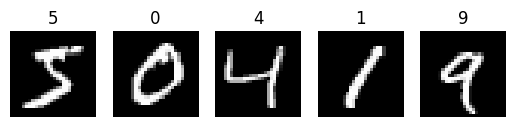

In [ ]:
# Display first 5 images
for i in range(5):
    image, label = train_data[i]

    plt.subplot(1, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(label)
    plt.axis("off")

plt.show()

In [ ]:
class MLP(nn.Module):
    def __init__(self, hidden_layers, activation):
        super().__init__()

        layers = []
        input_size = 28 * 28

        for size in hidden_layers:
            layers.append(nn.Linear(input_size, size))

            if activation == "ReLU":
                layers.append(nn.ReLU())
            else:
                layers.append(nn.Tanh())

            input_size = size

        # Output layer: 10 digit classes
        layers.append(nn.Linear(input_size, 10))

        self.model = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.model(x)

In [ ]:
def train_model(hidden_layers, activation, epochs=3):

    model = MLP(hidden_layers, activation)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_losses = []
    test_losses = []
    test_accuracies = []

    for epoch in range(epochs):

        # Training
        model.train()
        total_loss = 0

        for images, labels in train_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        train_losses.append(total_loss / len(train_loader))

        # Testing
        model.eval()
        correct = 0
        total = 0
        test_loss = 0

        with torch.no_grad():
            for images, labels in test_loader:
                outputs = model(images)
                loss = criterion(outputs, labels)

                test_loss += loss.item()

                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        test_losses.append(test_loss / len(test_loader))
        accuracy = 100 * correct / total
        test_accuracies.append(accuracy)

        print(
            f"Epoch {epoch+1}/{epochs}, "
            f"Train Loss: {train_losses[-1]:.4f}, "
            f"Test Accuracy: {accuracy:.2f}%"
        )

    return model, train_losses, test_losses, test_accuracies

In [ ]:
# Experiment 1
model1, train_loss1, test_loss1, acc1 = train_model(
    hidden_layers=[128],
    activation="ReLU",
    epochs=3
)

# Experiment 2
model2, train_loss2, test_loss2, acc2 = train_model(
    hidden_layers=[256, 128],
    activation="Tanh",
    epochs=3
)

Epoch 1/3, Train Loss: 0.3512, Test Accuracy: 93.96%
Epoch 2/3, Train Loss: 0.1630, Test Accuracy: 96.20%
Epoch 3/3, Train Loss: 0.1126, Test Accuracy: 96.90%
Epoch 1/3, Train Loss: 0.2916, Test Accuracy: 95.52%
Epoch 2/3, Train Loss: 0.1314, Test Accuracy: 96.59%
Epoch 3/3, Train Loss: 0.0887, Test Accuracy: 97.05%


In [ ]:
print("Model 1 - ReLU Accuracy:", acc1[-1], "%")
print("Model 2 - Tanh Accuracy:", acc2[-1], "%")

if acc1[-1] > acc2[-1]:
    print("Best Model: ReLU with 128 neurons")
else:
    print("Best Model: Tanh with 256 and 128 neurons")

Model 1 - ReLU Accuracy: 96.9 %
Model 2 - Tanh Accuracy: 97.05 %
Best Model: Tanh with 256 and 128 neurons


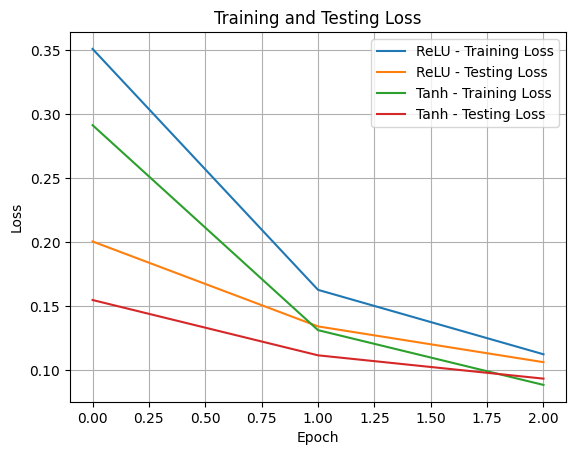

In [ ]:
plt.plot(train_loss1, label="ReLU - Training Loss")
plt.plot(test_loss1, label="ReLU - Testing Loss")

plt.plot(train_loss2, label="Tanh - Training Loss")
plt.plot(test_loss2, label="Tanh - Testing Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Testing Loss")
plt.legend()
plt.grid()
plt.show()

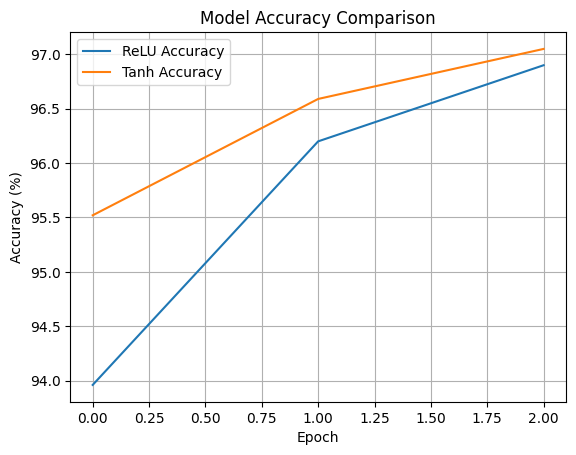

In [ ]:
plt.plot(acc1, label="ReLU Accuracy")
plt.plot(acc2, label="Tanh Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.legend()
plt.grid()
plt.show()

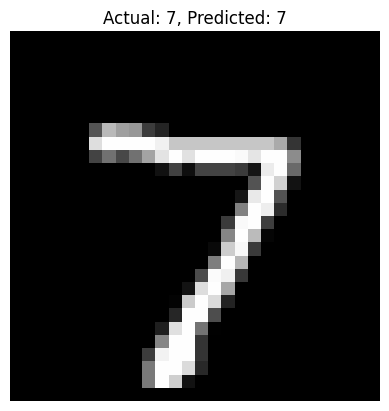

Actual Label: 7
Predicted Label: 7


In [ ]:
# Use the model with better test accuracy
if acc1[-1] > acc2[-1]:
    best_model = model1
else:
    best_model = model2

best_model.eval()

image, label = test_data[0]

with torch.no_grad():
    output = best_model(image.unsqueeze(0))
    prediction = torch.argmax(output, dim=1).item()

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual: {label}, Predicted: {prediction}")
plt.axis("off")
plt.show()

print("Actual Label:", label)
print("Predicted Label:", prediction)